# Beer Servings

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from pathlib import Path

import sklearn
print(sklearn.__version__)


1.7.2


In [2]:
data = pd.read_csv("beer-servings.csv")

# Remove the CSV's unnecessary index column, if present.
data = data.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset shape:", data.shape)
display(data.head())
print("\nColumn names:")
print(data.columns.tolist())


Dataset shape: (193, 6)


,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,Albania,89.0,132.0,54.0,4.9,Europe
2,Algeria,25.0,0.0,14.0,0.7,Africa
3,Andorra,245.0,138.0,312.0,12.4,Europe
4,Angola,217.0,57.0,45.0,5.9,Africa



Column names:
['country', 'beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol', 'continent']


### Inspect data types and missing values

In [3]:
display(data.info())
print("\nMissing values per column:")
display(data.isnull().sum())

print("\nSummary statistics:")
display(data.describe(include="all"))


<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       193 non-null    str    
 1   beer_servings                 185 non-null    float64
 2   spirit_servings               185 non-null    float64
 3   wine_servings                 187 non-null    float64
 4   total_litres_of_pure_alcohol  192 non-null    float64
 5   continent                     193 non-null    str    
dtypes: float64(4), str(2)
memory usage: 12.0 KB


None


Missing values per column:


country                         0
beer_servings                   8
spirit_servings                 8
wine_servings                   6
total_litres_of_pure_alcohol    1
continent                       0
dtype: int64


Summary statistics:


,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
count,193,185.000000,185.000000,187.000000,192.000000,193
unique,193,NaN,NaN,NaN,NaN,6
top,Afghanistan,NaN,NaN,NaN,NaN,Africa
freq,1,NaN,NaN,NaN,NaN,53
mean,NaN,105.124324,83.221622,50.165775,4.741667,NaN
std,NaN,100.524714,89.142958,80.358868,3.767654,NaN
min,NaN,0.000000,0.000000,0.000000,0.000000,NaN
25%,NaN,20.000000,4.000000,1.000000,1.300000,NaN
50%,NaN,76.000000,60.000000,9.000000,4.250000,NaN
75%,NaN,185.000000,132.000000,60.500000,7.200000,NaN


Basic data visualizations

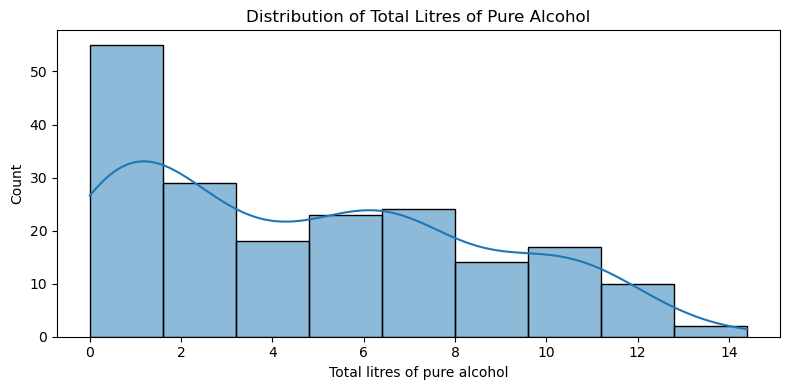

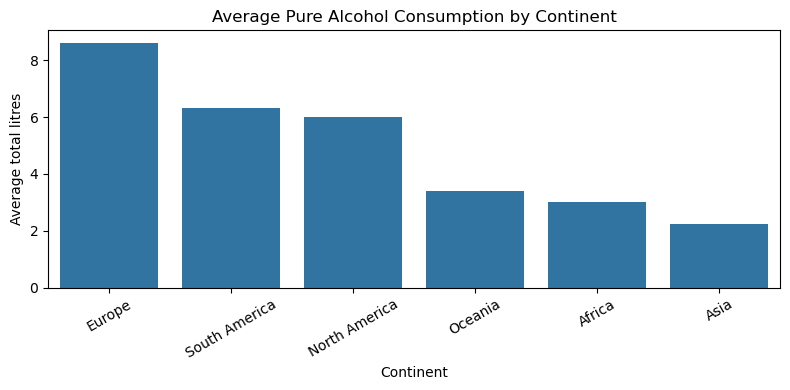

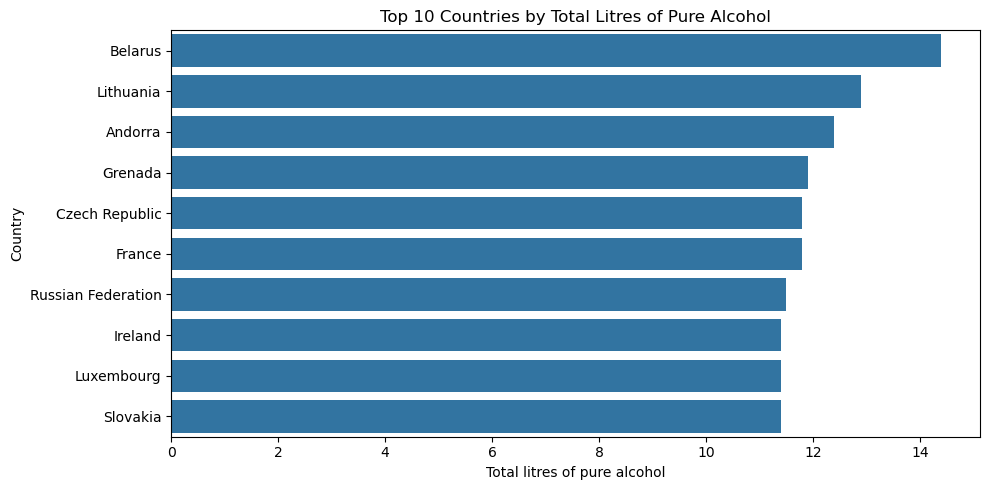

In [4]:
# Distribution of the target
plt.figure(figsize=(8, 4))
sns.histplot(data["total_litres_of_pure_alcohol"].dropna(), kde=True)
plt.title("Distribution of Total Litres of Pure Alcohol")
plt.xlabel("Total litres of pure alcohol")
plt.tight_layout()
plt.show()

# Average target by continent
continent_target = (
    data.groupby("continent", dropna=False)["total_litres_of_pure_alcohol"]
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(8, 4))
sns.barplot(x=continent_target.index, y=continent_target.values)
plt.title("Average Pure Alcohol Consumption by Continent")
plt.xlabel("Continent")
plt.ylabel("Average total litres")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Top countries by target (rows with target available)
top_countries = (
    data.dropna(subset=["total_litres_of_pure_alcohol"])
    .nlargest(10, "total_litres_of_pure_alcohol")
)
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_countries,
    x="total_litres_of_pure_alcohol",
    y="country"
)
plt.title("Top 10 Countries by Total Litres of Pure Alcohol")
plt.xlabel("Total litres of pure alcohol")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


## Prepare input features and target

In [5]:
target_column = "total_litres_of_pure_alcohol"

categorical_features = ["country", "continent"]
numerical_features = ["beer_servings", "spirit_servings", "wine_servings"]
feature_columns = categorical_features + numerical_features

data = data.dropna(subset=[target_column]).copy()

X = data[feature_columns].copy()
y = data[target_column].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nRemaining missing input values:")
display(X.isnull().sum())


X shape: (192, 5)
y shape: (192,)

Remaining missing input values:


country            0
continent          0
beer_servings      7
spirit_servings    7
wine_servings      5
dtype: int64

## Split into training and evaluation data

In [7]:
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training rows:", X_train.shape[0])
print("Evaluation rows:", X_test.shape[0])


Training rows: 153
Evaluation rows: 39


## Handle missing input values

In [8]:
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[numerical_features]),
    columns=numerical_features,
    index=X_train.index
)
X_test_num = pd.DataFrame(
    num_imputer.transform(X_test[numerical_features]),
    columns=numerical_features,
    index=X_test.index
)

X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[categorical_features]),
    columns=categorical_features,
    index=X_train.index
)
X_test_cat = pd.DataFrame(
    cat_imputer.transform(X_test[categorical_features]),
    columns=categorical_features,
    index=X_test.index
)

print("Missing numerical values in training data:", X_train_num.isnull().sum().sum())
print("Missing categorical values in training data:", X_train_cat.isnull().sum().sum())


Missing numerical values in training data: 0
Missing categorical values in training data: 0


## Encode categorical features

In [10]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded_train_array = encoder.fit_transform(X_train_cat)
encoded_test_array = encoder.transform(X_test_cat)

encoded_columns = encoder.get_feature_names_out(categorical_features)

X_train_encoded = pd.DataFrame(
    encoded_train_array,
    columns=encoded_columns,
    index=X_train.index
)
X_test_encoded = pd.DataFrame(
    encoded_test_array,
    columns=encoded_columns,
    index=X_test.index
)

print("Encoded categorical feature count:", len(encoded_columns))
display(X_train_encoded.head())


Encoded categorical feature count: 159


,country_Afghanistan,country_Albania,country_Algeria,country_Andorra,country_Angola,country_Argentina,country_Armenia,country_Australia,country_Azerbaijan,country_Bahamas,...,country_Vietnam,country_Yemen,country_Zambia,country_Zimbabwe,continent_Africa,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America
83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
110,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
163,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
136,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Scale numerical features

In [11]:
scaler = StandardScaler()

scaled_train_array = scaler.fit_transform(X_train_num)
scaled_test_array = scaler.transform(X_test_num)

X_train_scaled_num = pd.DataFrame(
    scaled_train_array,
    columns=numerical_features,
    index=X_train.index
)
X_test_scaled_num = pd.DataFrame(
    scaled_test_array,
    columns=numerical_features,
    index=X_test.index
)

# Combine encoded categorical columns and scaled numerical columns.
X_train_processed = pd.concat(
    [X_train_encoded, X_train_scaled_num], axis=1
)
X_test_processed = pd.concat(
    [X_test_encoded, X_test_scaled_num], axis=1
)

# Keep exactly the same feature order for train and evaluation data.
X_test_processed = X_test_processed.reindex(
    columns=X_train_processed.columns, fill_value=0
)

print("Processed training shape:", X_train_processed.shape)
print("Processed evaluation shape:", X_test_processed.shape)
display(X_train_processed.head())


Processed training shape: (153, 162)
Processed evaluation shape: (39, 162)


,country_Afghanistan,country_Albania,country_Algeria,country_Andorra,country_Angola,country_Argentina,country_Armenia,country_Australia,country_Azerbaijan,country_Bahamas,...,country_Zimbabwe,continent_Africa,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,beer_servings,spirit_servings,wine_servings
83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-0.206357,-0.463185,2.530772
110,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.436230,-0.367184,-0.380367
163,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.223406,1.168846,-0.526589
36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.266323,1.336849,-0.513296
136,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.883042,-0.265182,3.886644


## Linear Regression

In [12]:
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

linear_predictions = linear_model.predict(X_test_processed)

linear_r2 = r2_score(y_test, linear_predictions)
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)

print("Linear Regression")
print(f"Evaluation R²: {linear_r2:.4f}")
print(f"MAE:            {linear_mae:.4f}")
print(f"MSE:            {linear_mse:.4f}")
print(f"RMSE:           {linear_rmse:.4f}")


Linear Regression
Evaluation R²: 0.9468
MAE:            0.5263
MSE:            0.8949
RMSE:           0.9460


## Random Forest Regression and hyperparameter tuning

In [13]:
rf_model = RandomForestRegressor(random_state=RANDOM_STATE)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)

best_rf_model = grid_search.best_estimator_
rf_predictions = best_rf_model.predict(X_test_processed)

rf_r2 = r2_score(y_test, rf_predictions)
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)

print("Best Random Forest parameters:", grid_search.best_params_)
print(f"Best cross-validation R²: {grid_search.best_score_:.4f}")
print("\nTuned Random Forest — Evaluation Data")
print(f"Evaluation R²: {rf_r2:.4f}")
print(f"MAE:            {rf_mae:.4f}")
print(f"MSE:            {rf_mse:.4f}")
print(f"RMSE:           {rf_rmse:.4f}")


Best Random Forest parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best cross-validation R²: 0.7461

Tuned Random Forest — Evaluation Data
Evaluation R²: 0.8787
MAE:            0.8364
MSE:            2.0394
RMSE:           1.4281


## Compare models using evaluation R²

,Model,Evaluation R2,MAE,MSE,RMSE
0,Linear Regression,0.946760,0.526305,0.894897,0.945990
1,Tuned Random Forest,0.878668,0.836372,2.039422,1.428083


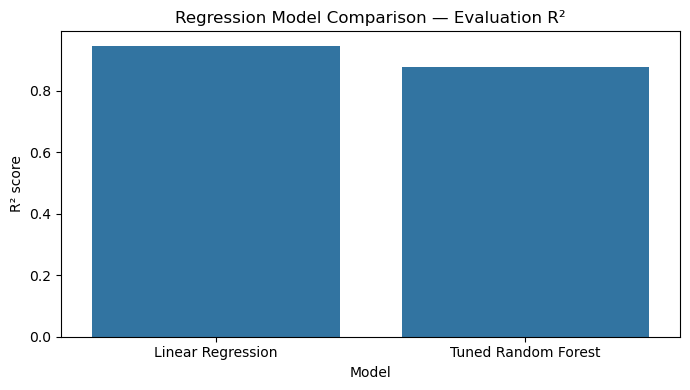

In [14]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Tuned Random Forest"],
    "Evaluation R2": [linear_r2, rf_r2],
    "MAE": [linear_mae, rf_mae],
    "MSE": [linear_mse, rf_mse],
    "RMSE": [linear_rmse, rf_rmse]
}).sort_values("Evaluation R2", ascending=False)

display(results)

plt.figure(figsize=(7, 4))
sns.barplot(data=results, x="Model", y="Evaluation R2")
plt.title("Regression Model Comparison — Evaluation R²")
plt.ylabel("R² score")
plt.xlabel("Model")
plt.tight_layout()
plt.show()


## Select the best model and save using joblib

In [15]:
if rf_r2 > linear_r2:
    best_model = best_rf_model
    best_model_name = "Tuned Random Forest"
    best_r2 = rf_r2
else:
    best_model = linear_model
    best_model_name = "Linear Regression"
    best_r2 = linear_r2

print("Selected model:", best_model_name)
print(f"Evaluation R²: {best_r2:.4f}")

# Save the selected regression model
joblib.dump(best_model, "best_model.pkl")

# Save the fitted preprocessing objects
joblib.dump(encoder, "encoder.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(num_imputer, "num_imputer.pkl")
joblib.dump(cat_imputer, "cat_imputer.pkl")

metadata = {
    "model_name": best_model_name,
    "evaluation_r2": float(best_r2),
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "feature_columns": feature_columns,
    "encoded_columns": list(encoded_columns),
    "countries": sorted(X["country"].dropna().unique().tolist()),
    "continents": sorted(X["continent"].dropna().unique().tolist())
}
joblib.dump(metadata, "model_metadata.pkl")

print("\nSaved files:")
for filename in [
    "best_model.pkl",
    "encoder.pkl",
    "scaler.pkl",
    "num_imputer.pkl",
    "cat_imputer.pkl",
    "model_metadata.pkl"
]:
    print("-", filename)


Selected model: Linear Regression
Evaluation R²: 0.9468

Saved files:
- best_model.pkl
- encoder.pkl
- scaler.pkl
- num_imputer.pkl
- cat_imputer.pkl
- model_metadata.pkl


## Test a prediction using the saved files

In [18]:
# Reload the model and preprocessing objects from disk.
loaded_model = joblib.load("best_model.pkl")
loaded_encoder = joblib.load("encoder.pkl")
loaded_scaler = joblib.load("scaler.pkl")
loaded_num_imputer = joblib.load("num_imputer.pkl")
loaded_cat_imputer = joblib.load("cat_imputer.pkl")

# Example input. Change these values to test other cases.
sample_input = pd.DataFrame([{
    "country": "India",
    "beer_servings": 10,
    "spirit_servings": 5,
    "wine_servings": 1,
    "continent": "Asia"
}])

sample_cat = pd.DataFrame(
    loaded_cat_imputer.transform(sample_input[categorical_features]),
    columns=categorical_features
)
sample_num = pd.DataFrame(
    loaded_num_imputer.transform(sample_input[numerical_features]),
    columns=numerical_features
)

sample_encoded_array = loaded_encoder.transform(sample_cat)
sample_encoded = pd.DataFrame(
    sample_encoded_array,
    columns=loaded_encoder.get_feature_names_out(categorical_features)
)

sample_scaled_array = loaded_scaler.transform(sample_num)
sample_scaled = pd.DataFrame(
    sample_scaled_array,
    columns=numerical_features
)

sample_processed = pd.concat(
    [sample_encoded, sample_scaled], axis=1
)
sample_processed = sample_processed.reindex(
    columns=X_train_processed.columns, fill_value=0
)

prediction = loaded_model.predict(sample_processed)[0]
print(f"Predicted total litres of pure alcohol: {prediction:.2f}")


Predicted total litres of pure alcohol: 0.64
